# Chapter 10: Differential flatness

This notebook reproduces the chapter's examples.

1. The weight on a string: where the hand must be.
2. The point that sees everything: the center of oscillation of a stick.
3. The quadrotor: the flat map in closed form, checked against the model and flown open loop.
4. The quadrotor with a cable-suspended load: the figure-eight for the load.
5. Cables with many links: the recursion from the free end.
6. From flat outputs to trajectories: minimum snap through waypoints.
7. What flatness gives a controller: the feedforward of the cascade.
8. Where it stops: zero thrust, zero tension, and a ripple.

Notation follows the book: $\dot R = R\,\Omega^\wedge$, $\dot q = \omega\times q$, the cable direction $q$ points
from the quadrotor to the load, $x_Q = x_L - l\,q$, gravity acts along $-e_3$.
Only NumPy, SciPy and Matplotlib are needed. The model functions are copied from the book's robot model
library (`case_studies/robots`), so that the notebook runs on its own.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

E1, E2, E3 = np.eye(3)
G = 9.81
rng = np.random.default_rng(10)


def hat(x):
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(A):
    return np.array([A[2, 1], A[0, 2], A[1, 0]])


def expm_so3(x):
    angle = np.linalg.norm(x)
    if angle < 1e-12:
        return np.eye(3) + hat(x)
    K = hat(x / angle)
    return np.eye(3) + np.sin(angle) * K + (1.0 - np.cos(angle)) * K @ K

**Derivatives without finite differences.** A flat map needs many time derivatives. We carry each quantity as a
truncated Taylor series (a *jet*): `a[k]` is the $k$-th Taylor coefficient, so the $k$-th derivative is $k!\,a_k$.
Products, quotients, square roots and unit vectors of jets are exact to rounding error.

In [2]:
def jmul(a, b, op=None):
    """Product of two jets (Cauchy product). op is the pointwise product:
    scalar times anything by default, or np.dot, np.cross, np.matmul."""
    K = min(len(a), len(b))
    if op is None:
        def op(x, y):
            return x * y if np.ndim(x) == 0 or np.ndim(y) == 0 or np.ndim(x) == np.ndim(y) \
                else x[..., None] * y
    out = [sum(op(a[i], b[k - i]) for i in range(k + 1)) for k in range(K)]
    return np.array(out)


def jdot(a, b):
    return jmul(a, b, np.dot)


def jcross(a, b):
    return jmul(a, b, np.cross)


def jsqrt(a):
    s = np.zeros(len(a))
    s[0] = math.sqrt(a[0])
    for k in range(1, len(a)):
        s[k] = (a[k] - sum(s[i] * s[k - i] for i in range(1, k))) / (2 * s[0])
    return s


def jdiv(a, b):
    """a / b for a scalar jet b."""
    K = min(len(a), len(b))
    d = np.zeros((K,) + np.shape(a[0]))
    for k in range(K):
        d[k] = (a[k] - sum(d[i] * b[k - i] for i in range(k))) / b[0]
    return d


def jnorm(a):
    return jsqrt(jdot(a, a))


def junit(a):
    return jdiv(a, jnorm(a))


def jder(a, times=1):
    """Jet of the time derivative: one order shorter each time."""
    for _ in range(times):
        a = np.array([(k + 1) * a[k + 1] for k in range(len(a) - 1)])
    return a


def jcossin(psi):
    """Jets of cos(psi) and sin(psi) for a scalar jet psi."""
    K = len(psi)
    c, s = np.zeros(K), np.zeros(K)
    c[0], s[0] = math.cos(psi[0]), math.sin(psi[0])
    for k in range(1, K):
        c[k] = -sum(j * psi[j] * s[k - j] for j in range(1, k + 1)) / k
        s[k] = sum(j * psi[j] * c[k - j] for j in range(1, k + 1)) / k
    return c, s


def derivs(a):
    """The time derivatives [a, a', a'', ...] of a jet."""
    return np.array([math.factorial(k) * a[k] for k in range(len(a))])


def jet_from_derivs(d):
    return np.array([np.asarray(d[k], float) / math.factorial(k) for k in range(len(d))])


class Trig:
    """x(t) = c0 + sum_j amp_j sin(rate_j t + phase_j), componentwise, with
    every derivative in closed form."""

    def __init__(self, c0, amp, rate, phase):
        self.c0 = np.asarray(c0, float)
        self.amp, self.rate, self.phase = (np.asarray(a, float) for a in (amp, rate, phase))

    def jet(self, t, order):
        out = []
        for k in range(order + 1):
            d = np.sum(self.amp * self.rate**k * np.sin(self.rate * t + self.phase + k * np.pi / 2),
                       axis=0)
            out.append((d + (self.c0 if k == 0 else 0.0)) / math.factorial(k))
        return np.array(out)

    def __call__(self, t):
        return self.jet(t, 0)[0]


def random_curve(rng, size=0.6, terms=3, shape=(3,), rate=(0.4, 1.6)):
    return Trig(rng.normal(size=shape), size * rng.normal(size=(terms,) + shape) / terms,
                rng.uniform(*rate, size=(terms,) + shape), rng.uniform(0, 2 * np.pi, size=(terms,) + shape))


def figure_eight(rate=1.0, a=1.2, b=0.6, c=0.15, z0=0.0):
    """The load path of the chapter: x_L = (a sin(rate t), b sin(2 rate t), z0 + c cos(2 rate t))."""
    return Trig([0.0, 0.0, z0], [[a, b, c]], [[rate, 2 * rate, 2 * rate]], [[0.0, 0.0, np.pi / 2]])

## 1. The weight on a string

The string must supply the missing force $m_L(\ddot x_L + g\,e_3)$, and it can only pull along itself. So

$$x_Q = x_L + l\,\frac{\ddot x_L + g\,e_3}{\|\ddot x_L + g\,e_3\|}.$$

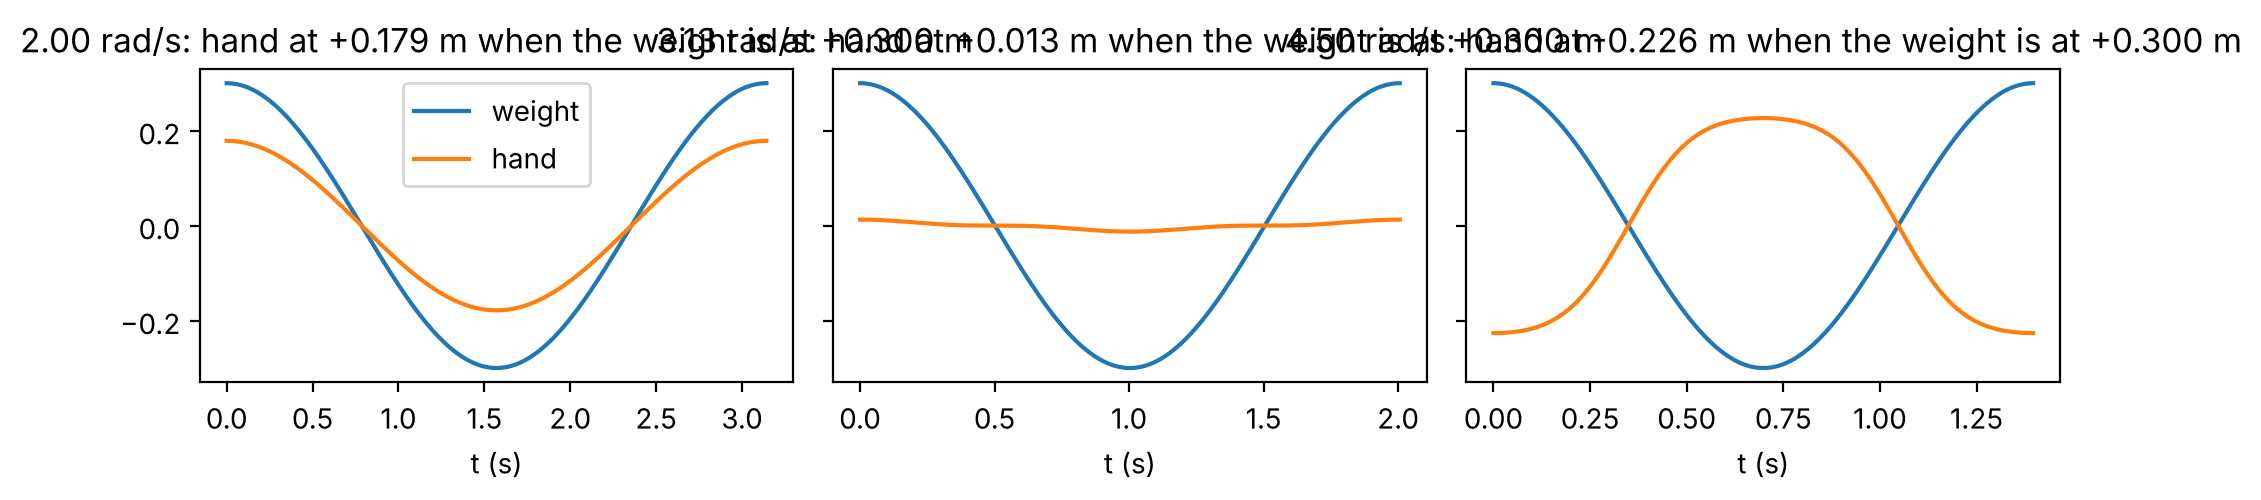

In [3]:
def hand_position(xw, l, g=G):
    """Where the hand must be for the weight (jet xw, order >= 2) to follow its path
    on a string of length l: x_hand = x + l (x'' + g e3)/|x'' + g e3|  (eq10-hand)."""
    A = jder(xw, 2)
    A[0] = A[0] + g * E3
    return xw[:len(A)] + l * junit(A)


l = 1.0
fig, ax = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for a, rate in zip(ax, (2.0, math.sqrt(G / l), 4.5)):
    path = Trig([0, 0, 0], [[0.3, 0, 0]], [[rate, 1, 1]], [[np.pi / 2, 0, 0]])     # x_L = 0.3 cos(rate t)
    ts = np.linspace(0, 2 * np.pi / rate, 200)
    hand = np.array([derivs(hand_position(path.jet(t, 2), l))[0] for t in ts])
    a.plot(ts, [path(t)[0] for t in ts], label="weight")
    a.plot(ts, hand[:, 0], label="hand")
    a.set_title(f"{rate:.2f} rad/s: hand at {hand[0, 0]:+.3f} m when the weight is at +0.300 m")
    a.set_xlabel("t (s)")
ax[0].legend()
plt.tight_layout()

## 2. The point that sees everything

A stick swung by one end behaves like a weight on a string of length $l = \|\rho\| + J/(m\|\rho\|)$: that point,
the center of oscillation, is a flat output. For a uniform stick of length 0.9 m it is at 0.6 m. We move the hand
by the formula above and integrate the stick's own equation of motion.

In [4]:
def string_run(P, L, times, h=1e-3):
    """A weight on a string of length L (or a stick whose center of oscillation is
    at L from the hand). The hand is moved as eq10-hand says for the curve P, and
    the pendulum's own equation, L alpha = q x (-(a_hand + g e3)), is integrated
    with a fourth-order step. Returns the simulated positions of the weight (or
    of the point at L) at the given times, and the hand positions."""
    def hand_acc(t):
        return derivs(jder(hand_position(P.jet(t, 6), L), 2))[0]

    def rhs(t, q, w):
        return np.cross(w, q), np.cross(q, -(hand_acc(t) + G * E3)) / L

    j = P.jet(0.0, 4)
    A = jder(j, 2)
    A[0] = A[0] + G * E3
    qj = -junit(A)
    q, w = qj[0], np.cross(qj[0], qj[1])
    out, hands, t = [], [], 0.0
    for t_next in times:
        steps = max(1, int(np.ceil((t_next - t) / h - 1e-9)))
        hs = (t_next - t) / steps                            # land exactly on t_next
        for _ in range(steps):
            k1 = rhs(t, q, w)
            k2 = rhs(t + hs / 2, q + hs / 2 * k1[0], w + hs / 2 * k1[1])
            k3 = rhs(t + hs / 2, q + hs / 2 * k2[0], w + hs / 2 * k2[1])
            k4 = rhs(t + hs, q + hs * k3[0], w + hs * k3[1])
            q = q + hs / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
            w = w + hs / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
            q = q / np.linalg.norm(q)
            t += hs
        hand = derivs(hand_position(P.jet(t, 2), L))[0]
        hands.append(hand)
        out.append(hand + L * q)
    return np.array(out), np.array(hands)


def stick_run(P, r, d, t_f, h=1e-3, aim=None):
    """A rigid stick swung in the vertical plane by its end. r: hand to center of
    mass, d = I_c/(m r), so that the point at r + d from the hand is the center of
    oscillation. The hand is moved by eq10-hand with string length `aim`
    (default r + d). Returns the largest distance between the point at `aim`
    and P(t)."""
    L = r + d
    aim = L if aim is None else aim
    times = np.arange(1, int(round(t_f / (10 * h))) + 1) * 10 * h
    if aim == L:
        pts, _ = string_run(P, L, times, h)
        return float(max(np.linalg.norm(p - P(t)) for p, t in zip(pts, times)))
    # hand moved for a string of length `aim`, stick still swings with length L
    def hand_acc(t):
        return derivs(jder(hand_position(P.jet(t, 6), aim), 2))[0]

    def rhs(t, q, w):
        return np.cross(w, q), np.cross(q, -(hand_acc(t) + G * E3)) / L
    j = P.jet(0.0, 4)
    A = jder(j, 2)
    A[0] = A[0] + G * E3
    qj = -junit(A)
    q, w, worst, t = qj[0], np.cross(qj[0], qj[1]), 0.0, 0.0
    for _ in range(int(round(t_f / h))):
        k1 = rhs(t, q, w)
        k2 = rhs(t + h / 2, q + h / 2 * k1[0], w + h / 2 * k1[1])
        k3 = rhs(t + h / 2, q + h / 2 * k2[0], w + h / 2 * k2[1])
        k4 = rhs(t + h, q + h * k3[0], w + h * k3[1])
        q = q + h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        w = w + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
        q = q / np.linalg.norm(q)
        t += h
        hand = derivs(hand_position(P.jet(t, 2), aim))[0]
        worst = max(worst, float(np.linalg.norm(hand + aim * q - P(t))))
    return worst


length = 0.9
r_c, d_c = length / 2, (length**2 / 12) / (length / 2)
P = Trig([0, 0, 0], [[0.4, 0.0, 0.1]], [[2.0, 1.0, 3.0]], [[0.0, 0.0, 0.5]])
print("center of oscillation at", r_c + d_c, "m")
print("aimed at the center of oscillation: miss of", stick_run(P, r_c, d_c, 5.0, h=2e-3), "m")
print("aimed at the tip:                   miss of", stick_run(P, r_c, d_c, 5.0, h=2e-3, aim=length), "m")

center of oscillation at 0.6 m


aimed at the center of oscillation: miss of 3.175525586717205e-12 m


aimed at the tip:                   miss of 0.04155649350572082 m


## 3. The quadrotor

Flat output: position $x$ and heading $\psi$. With $F = f R e_3 = m(\ddot x + g\,e_3)$,

$$f = \|F\|,\quad R e_3 = F/f,\quad R e_2 = \frac{R e_3\times R_z(\psi)e_1}{\|R e_3\times R_z(\psi)e_1\|},\quad R e_1 = R e_2\times R e_3,$$

$$\dot f = R e_3\cdot\dot F,\qquad \Omega_1 = -\frac{R e_2\cdot\dot F}{f},\qquad \Omega_2 = \frac{R e_1\cdot\dot F}{f},$$

$$\Omega_3 = \frac{\Omega_1\,(R e_3\cdot R_z(\psi)e_1) + \dot\psi\,(R e_2\cdot R_z(\psi)e_2)}{R e_1\cdot R_z(\psi)e_1},$$

$$\dot\Omega_1 = -\frac{R e_2\cdot\ddot F + 2\dot f\,\Omega_1}{f} + \Omega_2\Omega_3,\qquad
\dot\Omega_2 = \frac{R e_1\cdot\ddot F - 2\dot f\,\Omega_2}{f} - \Omega_1\Omega_3,$$

and $\tau = J\dot\Omega + \Omega\times J\Omega$. The function `quadrotor_flat_closed` writes these out, including
$\dot\Omega_3$. The function `quadrotor_flat` computes the same map with jets, by differentiating $R(t)$.

In [5]:
class QuadParams:                    # the vehicle of Chapter 6 (library: robots.quadrotor.Params)
    m = 4.34
    J = np.diag([0.0820, 0.0845, 0.1377])
    g = G


class LoadParams:                    # the worked example of Chapter 4 (library: robots.quadrotor_load.Params)
    m_Q, m_L, l = 1.5, 0.3, 1.0
    J = np.array([[0.02, 0.0005, 0.0], [0.0005, 0.025, 0.001], [0.0, 0.001, 0.04]])
    g = G


def quadrotor_dynamics(R, Omega, u, p):
    """(v_dot, Omega_dot) of the quadrotor, u = (f, tau). Copied from the library."""
    f, tau = u
    return f * R @ E3 / p.m - p.g * E3, np.linalg.solve(p.J, tau - np.cross(Omega, p.J @ Omega))


def load_dynamics(q, omega, R, Omega, u, p):
    """(v_L_dot, omega_dot, Omega_dot) of the quadrotor with a cable-suspended load. Copied from the library."""
    f, tau = u
    thrust = f * R @ E3
    q_dot = np.cross(omega, q)
    v_L_dot = (q @ thrust - p.m_Q * p.l * q_dot @ q_dot) * q / (p.m_Q + p.m_L) - p.g * E3
    omega_dot = -np.cross(q, thrust) / (p.m_Q * p.l)
    return v_L_dot, omega_dot, np.linalg.solve(p.J, tau - np.cross(Omega, p.J @ Omega))


def desired_attitude(F, heading):
    """Third axis along F, first axis as close to the heading as that allows."""
    b3 = F / np.linalg.norm(F)
    b2 = np.cross(b3, heading) / np.linalg.norm(np.cross(b3, heading))
    return np.column_stack([np.cross(b2, b3), b2, b3])


def attitude_from_force(F, psi, J):
    """From the jet of the thrust vector F = f R e3 (order >= 2) and of the heading
    angle psi_d (order >= 2): f, R (eq6-Rd), Omega, Omega_dot and tau (eq10-quad-map)."""
    K = min(len(F), len(psi))
    F, psi = F[:K], psi[:K]
    f = jnorm(F)
    b3 = jdiv(F, f)
    c, s = jcossin(psi)
    heading = np.stack([c, s, np.zeros(K)], axis=1)
    b2 = junit(jcross(b3, heading))
    b1 = jcross(b2, b3)
    R = np.stack([b1, b2, b3], axis=2)                       # jet of matrices, columns b_i
    Rt = np.transpose(R, (0, 2, 1))
    W = jmul(Rt[:K - 1], jder(R), np.matmul)                 # hat(Omega) = R' R_dot
    Omega = np.array([vee(0.5 * (w - w.T)) for w in W])
    Omega_dot = jder(Omega)
    Om, Omd = Omega[0], Omega_dot[0]
    return dict(f=f[0], R=R[0], Omega=Om, Omega_dot=Omd, tau=J @ Omd + np.cross(Om, J @ Om),
                f_jet=f, R_jet=R, Omega_jet=Omega, F=F[0])


def quadrotor_flat(x, psi, p):
    """eq10-quad-map. x: jet of the position, order >= 4. psi: jet of psi_d, order >= 2."""
    acc = jder(x, 2)
    acc[0] = acc[0] + p.g * E3
    out = attitude_from_force(p.m * acc, psi, p.J)
    d = derivs(x)
    out.update(x=d[0], v=d[1], a=d[2])
    return out


def quadrotor_flat_closed(d, psi, psi1, psi2, p):
    """The same map in closed form, eq10-quad-map to eq10-quad-Omega3-dot.
    d = [x, x', x'', x''', x'''']."""
    F, F1, F2 = p.m * (d[2] + p.g * E3), p.m * d[3], p.m * d[4]
    f = np.linalg.norm(F)
    b3 = F / f
    c = np.array([np.cos(psi), np.sin(psi), 0.0])
    cp = np.cross(E3, c)                                     # c_dot = psi_dot cp
    b2 = np.cross(b3, c) / np.linalg.norm(np.cross(b3, c))
    b1 = np.cross(b2, b3)
    f1 = b3 @ F1
    O1, O2 = -(b2 @ F1) / f, (b1 @ F1) / f
    O3 = (O1 * (b3 @ c) + psi1 * (b2 @ cp)) / (b1 @ c)
    Om = np.array([O1, O2, O3])
    O1d = -(b2 @ F2 + 2 * f1 * O1) / f + O2 * O3
    O2d = (b1 @ F2 - 2 * f1 * O2) / f - O1 * O3
    R = np.column_stack([b1, b2, b3])
    b1d, b2d, b3d = (R @ np.cross(Om, e) for e in (E1, E2, E3))
    num = (O1d * (b3 @ c) + O1 * (b3d @ c + psi1 * (b3 @ cp)) + psi2 * (b2 @ cp)
           + psi1 * (b2d @ cp) - O3 * (b1d @ c + psi1 * (b1 @ cp)))
    Omd = np.array([O1d, O2d, num / (b1 @ c)])
    return dict(f=f, R=R, Omega=Om, Omega_dot=Omd, tau=p.J @ Omd + np.cross(Om, p.J @ Om),
                f_dot=f1, f_ddot=b3 @ F2 + f * (O1**2 + O2**2))

In [6]:
p = QuadParams()
worst = 0.0
for _ in range(20):
    x, psi = random_curve(rng), random_curve(rng, shape=())
    t = rng.uniform(0, 10)
    o = quadrotor_flat(x.jet(t, 4), psi.jet(t, 2), p)
    d, dp = derivs(x.jet(t, 4)), derivs(psi.jet(t, 2))
    c = quadrotor_flat_closed(d, dp[0], dp[1], dp[2], p)
    acc = quadrotor_dynamics(o["R"], o["Omega"], (o["f"], o["tau"]), p)
    worst = max(worst, np.abs(acc[0] - o["a"]).max(), np.abs(acc[1] - o["Omega_dot"]).max(),
                *(np.abs(o[k] - c[k]).max() for k in ("f", "R", "Omega", "Omega_dot", "tau")))
print("closed form against jets, and both against the model:", worst)

closed form against jets, and both against the model: 8.881784197001252e-16


**Open loop.** Feed $f(t)$, $\tau(t)$ to the model with no feedback, on the reference of Chapter 6: a circle of
radius 1.5 m flown at 1 rad/s with a vertical wobble, heading along the tangent.

In [7]:
def circle_reference(t, rate=1.0, radius=1.5):
    """Position and its first four derivatives, then the heading vector and its first two."""
    c, s = np.cos(rate * t), np.sin(rate * t)
    c2, s2 = np.cos(2 * rate * t), np.sin(2 * rate * t)
    xd = np.array([radius * c, radius * s, 0.3 * s2])
    vd = np.array([-radius * rate * s, radius * rate * c, 0.6 * rate * c2])
    ad = np.array([-radius * rate**2 * c, -radius * rate**2 * s, -1.2 * rate**2 * s2])
    jd = np.array([radius * rate**3 * s, -radius * rate**3 * c, -2.4 * rate**3 * c2])
    sd = np.array([radius * rate**4 * c, radius * rate**4 * s, 4.8 * rate**4 * s2])
    psi = rate * t + np.pi / 2
    hd = np.array([np.cos(psi), np.sin(psi), 0.0])
    return xd, vd, ad, jd, sd, hd, rate * np.array([-np.sin(psi), np.cos(psi), 0.0]), -rate**2 * hd


def circle_flat(t, p):
    ref = circle_reference(t)
    return ref, quadrotor_flat_closed(ref[:5], t + np.pi / 2, 1.0, 0.0, p)


def quad_rhs(t, s, law, p):
    x, v, R, Omega = s[:3], s[3:6], s[6:15].reshape(3, 3), s[15:18]
    v_dot, Omega_dot = quadrotor_dynamics(R, Omega, law(t, x, v, R, Omega), p)
    return np.concatenate([v, v_dot, (R @ hat(Omega)).ravel(), Omega_dot])


def open_loop_law(t, x, v, R, Omega):
    o = circle_flat(t, p)[1]
    return o["f"], o["tau"]


ref0, o0 = circle_flat(0.0, p)
s0 = np.concatenate([ref0[0], ref0[1], o0["R"].ravel(), o0["Omega"]])
sol = solve_ivp(quad_rhs, [0, 10], s0, args=(open_loop_law, p), rtol=1e-11, atol=1e-12)
print("open loop, after 10 s: distance from the curve", np.linalg.norm(sol.y[:3, -1] - circle_reference(10.0)[0]), "m")
tilted = s0.copy()
tilted[6:15] = (o0["R"] @ expm_so3(np.radians(1.0) * E1)).ravel()
sol = solve_ivp(quad_rhs, [0, 5], tilted, args=(open_loop_law, p), rtol=1e-10, atol=1e-12)
print("released with 1 deg of tilt error, after 5 s:", np.linalg.norm(sol.y[:3, -1] - circle_reference(5.0)[0]), "m")

open loop, after 10 s: distance from the curve 4.257467939330056e-11 m


released with 1 deg of tilt error, after 5 s: 2.085059503958345 m


## 4. The quadrotor with a cable-suspended load

Flat output: the load position $x_L$ and the heading. Three rungs:

$$T = m_L\|\ddot x_L + g\,e_3\|,\qquad q = -\frac{\ddot x_L + g\,e_3}{\|\ddot x_L + g\,e_3\|},\qquad x_Q = x_L - l\,q,$$

$$F = f R e_3 = m_Q(\ddot x_Q + g\,e_3) + m_L(\ddot x_L + g\,e_3),$$

and then the quadrotor's map with this $F$. The torque needs $x_L^{(6)}$.

flat map of the load against the model: 3.164135620181696e-15


two laps open loop: largest distance of the load from its curve 9.890812335822119e-10 m


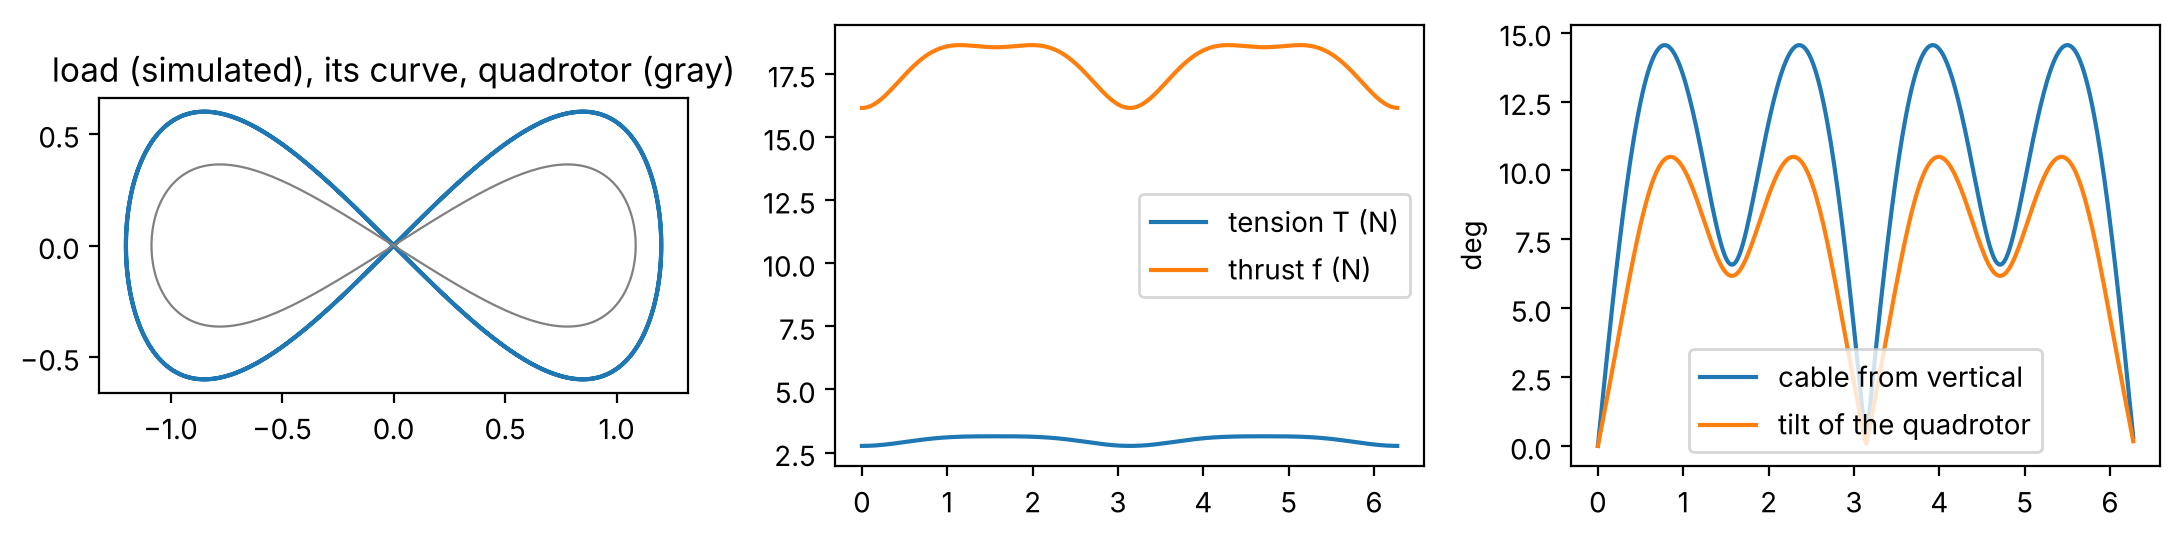

In [8]:
def load_flat(xL, psi, p):
    """eq10-load-map. xL: jet of the load position, order >= 6."""
    A = jder(xL, 2)
    A[0] = A[0] + p.g * E3
    A = p.m_L * A                                           # -T q = m_L (x_L'' + g e3)
    T = jnorm(A)
    q = -jdiv(A, T)
    K = len(q)
    xQ = xL[:K] - p.l * q
    accQ = jder(xQ, 2)
    accQ[0] = accQ[0] + p.g * E3
    F = p.m_Q * accQ + A[:K - 2]                            # f R e3
    out = attitude_from_force(F, psi, p.J)
    qd = derivs(q)
    d = derivs(xL)
    out.update(x_L=d[0], v_L=d[1], a_L=d[2], q=qd[0], omega=np.cross(qd[0], qd[1]),
               omega_dot=np.cross(qd[0], qd[2]), T=T[0], x_Q=xQ[0], q_jet=q, T_jet=T, xQ_jet=xQ)
    return out


pl = LoadParams()
eight = figure_eight()                      # x_L = (1.2 sin t, 0.6 sin 2t, 0.15 cos 2t)
psi0 = np.zeros(3)
worst = 0.0
for _ in range(20):
    x, psi = random_curve(rng), random_curve(rng, shape=())
    t = rng.uniform(0, 10)
    o = load_flat(x.jet(t, 6), psi.jet(t, 2), pl)
    acc = load_dynamics(o["q"], o["omega"], o["R"], o["Omega"], (o["f"], o["tau"]), pl)
    worst = max(worst, *(np.abs(a - b).max() for a, b in zip(acc, (o["a_L"], o["omega_dot"], o["Omega_dot"]))))
print("flat map of the load against the model:", worst)


def load_rhs(t, s, path, p):
    x, v, q, om, R, Om = s[:3], s[3:6], s[6:9], s[9:12], s[12:21].reshape(3, 3), s[21:24]
    o = load_flat(path.jet(t, 6), psi0, p)
    v_dot, om_dot, Om_dot = load_dynamics(q, om, R, Om, (o["f"], o["tau"]), p)
    return np.concatenate([v, v_dot, np.cross(om, q), om_dot, (R @ hat(Om)).ravel(), Om_dot])


o0 = load_flat(eight.jet(0.0, 6), psi0, pl)
s0 = np.concatenate([o0["x_L"], o0["v_L"], o0["q"], o0["omega"], o0["R"].ravel(), o0["Omega"]])
ts = np.linspace(0, 4 * np.pi, 600)
sol = solve_ivp(load_rhs, [0, ts[-1]], s0, t_eval=ts, args=(eight, pl), rtol=1e-11, atol=1e-12)
want = np.array([eight(t) for t in ts])
print("two laps open loop: largest distance of the load from its curve",
      np.abs(sol.y[:3].T - want).max(), "m")
O = [load_flat(eight.jet(t, 6), psi0, pl) for t in ts[:300]]
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].plot(want[:, 0], want[:, 1], "k--", lw=0.8)
ax[0].plot(sol.y[0], sol.y[1])
ax[0].plot([o["x_Q"][0] for o in O], [o["x_Q"][1] for o in O], color="gray", lw=0.8)
ax[0].set_title("load (simulated), its curve, quadrotor (gray)")
ax[0].set_aspect("equal")
ax[1].plot(ts[:300], [o["T"] for o in O], label="tension T (N)")
ax[1].plot(ts[:300], [o["f"] for o in O], label="thrust f (N)")
ax[1].legend()
ax[2].plot(ts[:300], [np.degrees(np.arccos(-o["q"][2])) for o in O], label="cable from vertical")
ax[2].plot(ts[:300], [np.degrees(np.arccos(o["R"][2, 2])) for o in O], label="tilt of the quadrotor")
ax[2].set_ylabel("deg")
ax[2].legend()
plt.tight_layout()

## 5. Cables with many links

Joint 0 is the quadrotor and joint $n$ the free end. Link $i$ points from joint $i-1$ to joint $i$. From the free
end upward,

$$T_i\,q_i = T_{i+1}\,q_{i+1} - m_i(\ddot x_i + g\,e_3),\qquad x_{i-1} = x_i - l_i\,q_i,\qquad i = n, \dots, 1,$$

with $T_{n+1} = 0$, and at the top $F = (m_Q + m_0)(\ddot x_0 + g\,e_3) - T_1 q_1$. Each link costs two derivatives:
the torque needs $x_n^{(2n+4)}$. The model below is the library's `quadrotor_cable` with one quadrotor at joint 0.

In [9]:
def chain_flat(xn, psi, mass, l, J, g=G, attach=(0,), pulls=None):
    """thm10-chain. Joints 0..n, link i from joint i - 1 to joint i with direction
    q_i, a free end at joint n, quadrotors at the joints in `attach` (joint 0 always).
    xn: jet of the free end, order >= 2 n + 4. mass[k]: mass at joint k, an attached
    quadrotor included. psi: one heading jet per quadrotor (or a single jet).
    pulls[k]: jet of the tension vector T_k q_k of link k, for every attached k >= 1;
    these are flat outputs. Returns link directions, tensions, and for each
    quadrotor (in the order of `attach`) its attitude, velocity and input."""
    n = len(l)
    psis = [psi] * len(attach) if np.ndim(psi[0]) == 0 and np.ndim(psi) == 1 else list(psi)
    Js = [J] * len(attach) if np.ndim(J) == 2 else list(J)
    x, pull = xn, None                                      # pull = T_i q_i
    q, T, quads = [None] * n, [None] * n, {}

    def weight(x, k):
        A = jder(x, 2)
        A[0] = A[0] + g * E3
        return mass[k] * A

    for i in range(n, 0, -1):
        A = weight(x, i)
        below = 0.0 * A if pull is None else pull[:len(A)]
        if i in attach:                                     # the tension above is given
            pull = pulls[i]
            K = min(len(A), len(pull))
            quads[i] = A[:K] + pull[:K] - below[:K]         # f_i R_i e3
        else:                                               # T_i q_i = T_{i+1} q_{i+1} - m_i (x_i'' + g e3)
            pull = below - A
        T[i - 1] = jnorm(pull)
        q[i - 1] = jdiv(pull, T[i - 1])
        K = min(len(x), len(pull))
        x = x[:K] - l[i - 1] * q[i - 1][:K]                 # x_{i-1} = x_i - l_i q_i
    A = weight(x, 0)
    quads[0] = A - pull[:len(A)]
    att = [attitude_from_force(quads[k], psis[j], Js[j]) for j, k in enumerate(attach)]
    qd = [derivs(qi) for qi in q]
    out = dict(x_0=derivs(x)[0], v_0=derivs(x)[1], a_0=derivs(x)[2],
               q=np.array([d[0] for d in qd]),
               omega=np.array([np.cross(d[0], d[1]) for d in qd]),
               omega_dot=np.array([np.cross(d[0], d[2]) for d in qd]),
               T=np.array([Ti[0] for Ti in T]))
    for key in ("f", "R", "Omega", "Omega_dot", "tau"):
        out[key] = np.array([a[key] for a in att])
    return out


def cable_dynamics(q, omega, R, Omega, u, mass, l, J, g=G):
    """(x_0_ddot, omega_dot, Omega_dot) of a chain of n links under one quadrotor at joint 0.
    mass[k] is the mass at joint k, the quadrotor included in mass[0]. Copied from the library."""
    f, tau = u
    n = len(l)
    below = np.cumsum(mass[::-1])[::-1]
    M = np.array([[below[1 + max(i, j)] * l[i] * l[j] for j in range(n)] for i in range(n)])
    M0 = l * below[1:]
    A, b = np.zeros((3 + 3 * n, 3 + 3 * n)), np.zeros(3 + 3 * n)
    A[:3, :3] = below[0] * np.eye(3)
    b[:3] = f * R @ E3
    for j in range(n):
        cols = slice(3 + 3 * j, 6 + 3 * j)
        A[:3, cols] = -M0[j] * hat(q[j])
        b[:3] += M0[j] * (omega[j] @ omega[j]) * q[j]
    for i in range(n):
        rows = slice(3 + 3 * i, 6 + 3 * i)
        A[rows, :3] = M0[i] * hat(q[i])
        for j in range(n):
            cols = slice(3 + 3 * j, 6 + 3 * j)
            A[rows, cols] = -M[i, j] * hat(q[i]) @ hat(q[j])
            b[rows] += M[i, j] * (omega[j] @ omega[j]) * np.cross(q[i], q[j])
        A[rows, rows] += M[i, i] * np.outer(q[i], q[i])
    z = np.linalg.solve(A, b)
    return z[:3] - g * E3, z[3:].reshape(n, 3), np.linalg.solve(J, tau - np.cross(Omega, J @ Omega))


for n in (1, 2, 3):
    mass = np.array([1.5] + [0.2] * (n - 1) + [0.3])
    l = np.full(n, 1.2 / n)
    worst = 0.0
    for _ in range(10):
        x, psi = random_curve(rng, size=0.5), random_curve(rng, shape=())
        t = rng.uniform(0, 10)
        o = chain_flat(x.jet(t, 2 * n + 4), psi.jet(t, 2), mass, l, pl.J)
        acc = cable_dynamics(o["q"], o["omega"], o["R"][0], o["Omega"][0], (o["f"][0], o["tau"][0]), mass, l, pl.J)
        worst = max(worst, *(np.abs(a - b).max() for a, b in zip(acc, (o["a_0"], o["omega_dot"], o["Omega_dot"][0]))))
    print(f"n = {n}: uses derivatives up to order {2 * n + 4}, residual in the model {worst:.1e}")

n = 1: uses derivatives up to order 6, residual in the model 4.4e-15
n = 2: uses derivatives up to order 8, residual in the model 2.6e-15
n = 3: uses derivatives up to order 10, residual in the model 5.3e-15


## 6. From flat outputs to trajectories

Minimum snap through waypoints: pieces of degree seven, at rest at both ends, continuity up to the third
derivative imposed. The cost is a quadratic form in the coefficients and the conditions are linear, so the
minimizer is the solution of one linear (KKT) system. The same function with `r=6` minimizes the sixth derivative,
for the load.

quadratic program against the degree-7 spline system: 1.1812772982011666e-12
jump of derivatives 0..7 at the first waypoint: [  0.           0.           0.           0.           0.
   0.           0.         678.25824015]


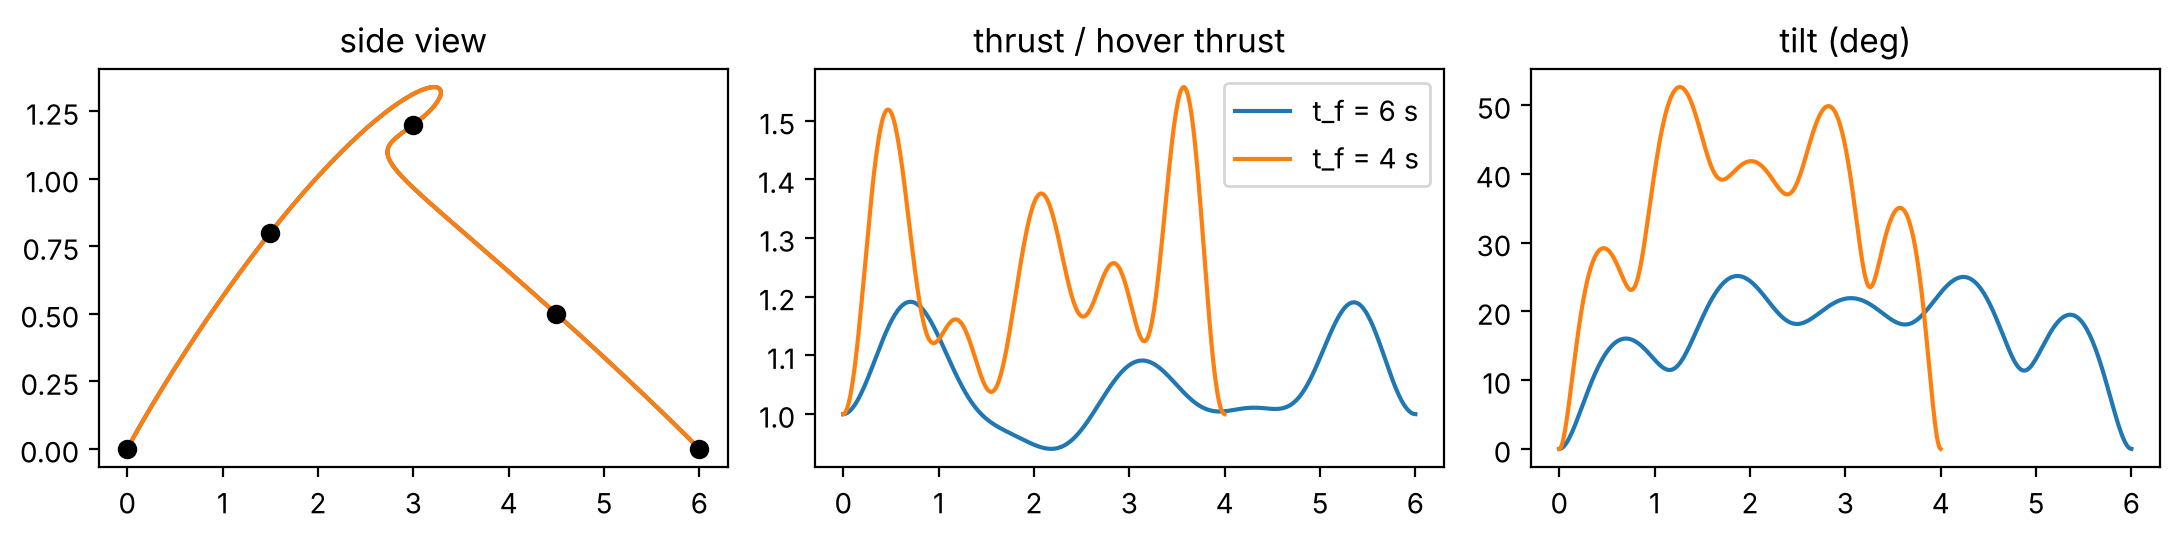

In [10]:
def _basis(s, k, deg):
    """Row of d^k/ds^k of (1, s, ..., s^deg)."""
    row = np.zeros(deg + 1)
    for j in range(k, deg + 1):
        row[j] = math.factorial(j) / math.factorial(j - k) * s ** (j - k)
    return row


def _constraints(n_seg, dur, r, smooth):
    """Linear constraints A c = b(w) on the stacked coefficients of one axis:
    interpolation, rest at both ends (derivatives 1..r-1 zero) and continuity of
    derivatives 1..smooth at the interior waypoints. Returns A and a function b(w)."""
    deg, rows, kinds = 2 * r - 1, [], []

    def row(i, s, k):
        z = np.zeros(n_seg * (deg + 1))
        z[i * (deg + 1):(i + 1) * (deg + 1)] = _basis(s, k, deg) / dur[i] ** k
        return z

    for i in range(n_seg):
        rows += [row(i, 0.0, 0), row(i, 1.0, 0)]
        kinds += [("w", i), ("w", i + 1)]
    for k in range(1, r):
        rows += [row(0, 0.0, k), row(n_seg - 1, 1.0, k)]
        kinds += [("0",), ("0",)]
    for i in range(n_seg - 1):
        for k in range(1, smooth + 1):
            rows.append(row(i, 1.0, k) - row(i + 1, 0.0, k))
            kinds.append(("0",))
    A = np.array(rows)

    def b(w):
        return np.array([w[kd[1]] if kd[0] == "w" else 0.0 for kd in kinds])
    return A, b


def _cost(n_seg, dur, r):
    """P with c' P c = integral of (x^(r))^2 over all segments, one axis."""
    deg = 2 * r - 1
    P = np.zeros((n_seg * (deg + 1),) * 2)
    for i in range(n_seg):
        for j in range(r, deg + 1):
            for k in range(r, deg + 1):
                cj = math.factorial(j) / math.factorial(j - r)
                ck_ = math.factorial(k) / math.factorial(k - r)
                P[i * (deg + 1) + j, i * (deg + 1) + k] = cj * ck_ / (j + k - 2 * r + 1) * dur[i] ** (1 - 2 * r)
    return P


class Spline:
    """Piecewise polynomial of degree 2 r - 1 through waypoints at given times."""

    def __init__(self, coeff, times, r):
        self.coeff, self.times, self.r = coeff, np.asarray(times, float), r   # coeff: (n_seg, deg + 1, dim)
        self.dur = np.diff(self.times)

    def jet(self, t, order):
        i = int(np.clip(np.searchsorted(self.times, t, side="right") - 1, 0, len(self.dur) - 1))
        s = (t - self.times[i]) / self.dur[i]
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def jet_side(self, i, s, order):
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def __call__(self, t):
        return self.jet(t, 0)[0]

    def cost(self):
        P = _cost(len(self.dur), self.dur, self.r)
        c = self.coeff.reshape(-1, self.coeff.shape[2])
        return float(np.trace(c.T @ P @ c))


def min_derivative_spline(waypoints, times, r=4, method="qp"):
    """The curve through the waypoints at the given times, at rest at both ends,
    that minimizes the integral of |x^(r)|^2 (r = 4: minimum snap).

    method "qp": quadratic program with continuity up to order r - 1 imposed,
    solved through its KKT system (eq10-minsnap).
    method "spline": no optimization. The square linear system that asks for
    continuity up to order 2 r - 2, which the minimizer has on its own."""
    w = np.asarray(waypoints, float)
    times = np.asarray(times, float)
    n_seg, dur, deg = len(w) - 1, np.diff(times), 2 * r - 1
    if method == "qp":
        A, b = _constraints(n_seg, dur, r, r - 1)
        P = _cost(n_seg, dur, r)
        KKT = np.block([[2 * P, A.T], [A, np.zeros((len(A), len(A)))]])
        sol = np.column_stack([np.linalg.solve(KKT, np.concatenate([np.zeros(P.shape[0]), b(w[:, d])]))
                               for d in range(w.shape[1])])
        c = sol[:P.shape[0]]
    else:
        A, b = _constraints(n_seg, dur, r, 2 * r - 2)
        c = np.column_stack([np.linalg.solve(A, b(w[:, d])) for d in range(w.shape[1])])
    return Spline(c.reshape(n_seg, deg + 1, w.shape[1]), times, r)


def chord_times(waypoints, t_f):
    """Waypoint times proportional to chord length, from 0 to t_f."""
    d = np.linalg.norm(np.diff(np.asarray(waypoints, float), axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(d)]) * t_f / np.sum(d)


W = np.array([[0.0, 0.0, 0.0], [1.5, 1.0, 0.8], [3.0, -0.8, 1.2], [4.5, 0.6, 0.5], [6.0, 0.0, 0.0]])
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for t_f in (6.0, 4.0):
    sp = min_derivative_spline(W, chord_times(W, t_f), 4)
    ts = np.linspace(0, t_f, 400)
    O = [quadrotor_flat(sp.jet(t, 4), psi0, p) for t in ts]
    X = np.array([o["x"] for o in O])
    ax[0].plot(X[:, 0], X[:, 2])
    ax[1].plot(ts, [o["f"] / (p.m * p.g) for o in O], label=f"t_f = {t_f:g} s")
    ax[2].plot(ts, [np.degrees(np.arccos(o["R"][2, 2])) for o in O])
ax[0].plot(W[:, 0], W[:, 2], "ko")
ax[0].set_title("side view")
ax[1].set_title("thrust / hover thrust")
ax[1].legend()
ax[2].set_title("tilt (deg)")
plt.tight_layout()

tm = chord_times(W, 6.0)
qp, direct = min_derivative_spline(W, tm, 4, "qp"), min_derivative_spline(W, tm, 4, "spline")
print("quadratic program against the degree-7 spline system:", np.abs(qp.coeff - direct.coeff).max())
jump = [np.abs(derivs(qp.jet_side(0, 1.0, 7)) - derivs(qp.jet_side(1, 0.0, 7))).max(axis=1)]
print("jump of derivatives 0..7 at the first waypoint:", np.round(jump[0], 8))

## 7. What flatness gives a controller

The cascade of Chapter 6 on the circle, from a 5 cm offset, with Lee's gains scaled by $(\kappa^2, \kappa)$ in the
attitude loop. `zero`: $\Omega_d = \dot\Omega_d = 0$. `flat`: $\Omega_d$, $\dot\Omega_d$ of the reference, from the
flat map. The attitude reference $R_d$ is built from $F_d$ in both.

zero  x1: diverged at 14.6 s


flat  x1: diverged at 9.2 s


zero  x1.5: error 1.8e-02 m at 15 s


flat  x1.5: error 2.2e-05 m at 15 s


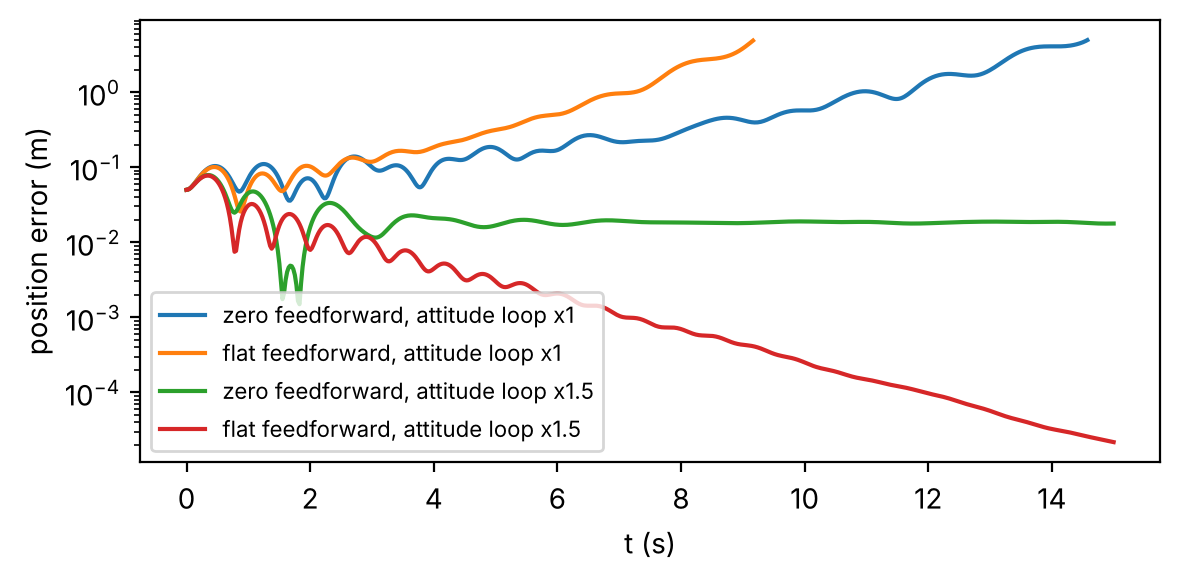

In [11]:
k_x, k_v, k_R, k_Omega = 16 * 4.34, 5.6 * 4.34, 8.81, 2.54


def cascade_law(mode, speedup):
    def law(t, x, v, R, Omega):
        ref, o = circle_flat(t, p)
        Fd = -k_x * (x - ref[0]) - k_v * (v - ref[1]) + p.m * p.g * E3 + p.m * ref[2]
        Rd = desired_attitude(Fd, ref[5])
        Omegad, Omegad_dot = (o["Omega"], o["Omega_dot"]) if mode == "flat" else (np.zeros(3), np.zeros(3))
        e_R = 0.5 * vee(Rd.T @ R - R.T @ Rd)
        e_Omega = Omega - R.T @ Rd @ Omegad
        tau = (-speedup**2 * k_R * e_R - speedup * k_Omega * e_Omega + np.cross(Omega, p.J @ Omega)
               - p.J @ (np.cross(Omega, R.T @ Rd @ Omegad) - R.T @ Rd @ Omegad_dot))
        return Fd @ (R @ E3), tau
    return law


def cascade_run(mode, speedup, t_f=15.0):
    ref0 = circle_reference(0.0)
    Rz90 = np.array([[0.0, -1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    s0 = np.concatenate([ref0[0] + [0.05, 0, 0], ref0[1], Rz90.ravel(), np.zeros(3)])

    def lost(t, s, *a):
        return 5.0 - np.linalg.norm(s[:3] - circle_reference(t)[0])
    lost.terminal = True
    ts = np.linspace(0, t_f, 600)
    sol = solve_ivp(quad_rhs, [0, t_f], s0, t_eval=ts, args=(cascade_law(mode, speedup), p), rtol=1e-9, atol=1e-11,
                    events=lost, max_step=0.02)
    return sol.t, np.array([np.linalg.norm(s[:3] - circle_reference(t)[0]) for t, s in zip(sol.t, sol.y.T)])


plt.figure(figsize=(6, 3))
for mode, speedup in (("zero", 1.0), ("flat", 1.0), ("zero", 1.5), ("flat", 1.5)):
    ts, es = cascade_run(mode, speedup)
    plt.semilogy(ts, es, label=f"{mode} feedforward, attitude loop x{speedup:g}")
    print(f"{mode:5s} x{speedup:g}: " + (f"diverged at {ts[-1]:.1f} s" if ts[-1] < 14.9 else f"error {es[-1]:.1e} m at 15 s"))
plt.xlabel("t (s)")
plt.ylabel("position error (m)")
plt.legend(fontsize=8)
plt.tight_layout()

## 8. Where it stops

The figure-eight flown faster. The thrust vanishes at the crossing point at 1.72 rad/s, long before the tension
does (4.04 rad/s). Then a ripple of 1 mm at 2 Hz on the load's curve.

largest torque, clean curve:     0.01588273578206231 N·m


largest torque, 1 mm at 2 Hz:    0.8812943818552952 N·m


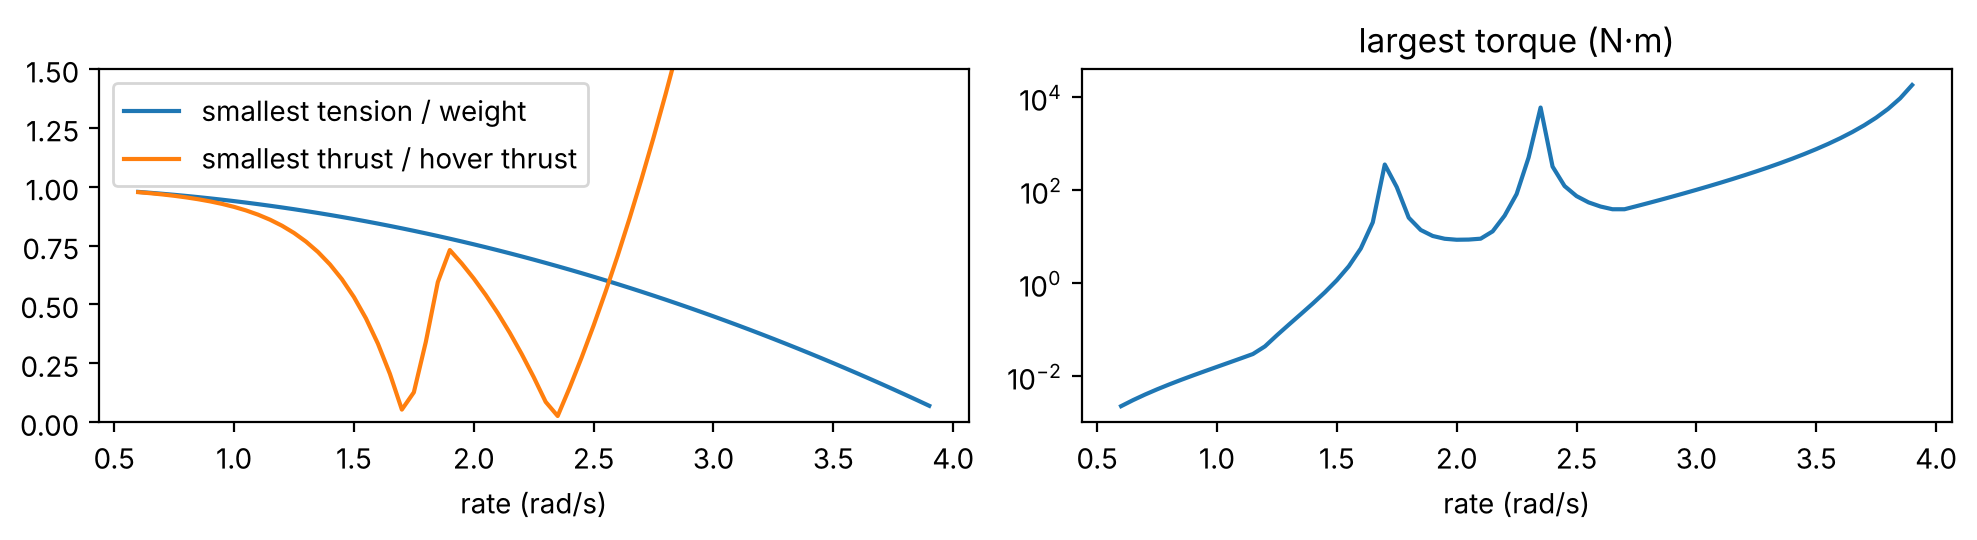

In [12]:
def lap_stats(path, rate, n=721):
    O = [load_flat(path.jet(t, 6), psi0, pl) for t in np.linspace(0, 2 * np.pi / rate, n)]
    return (min(o["T"] for o in O), min(o["f"] for o in O), max(np.linalg.norm(o["tau"]) for o in O))


rates = np.linspace(0.6, 3.9, 67)
S = np.array([lap_stats(figure_eight(rate=r), r) for r in rates])
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].plot(rates, S[:, 0] / (pl.m_L * G), label="smallest tension / weight")
ax[0].plot(rates, S[:, 1] / ((pl.m_Q + pl.m_L) * G), label="smallest thrust / hover thrust")
ax[0].set_ylim(0, 1.5)
ax[0].legend()
ax[1].semilogy(rates, S[:, 2])
ax[1].set_title("largest torque (N·m)")
for a in ax:
    a.set_xlabel("rate (rad/s)")
plt.tight_layout()

w_r = 2 * np.pi * 2.0
ripple = Trig([0, 0, 0], [[1.2, 0.6, 0.15], [1e-3, 0.0, 0.0]], [[1.0, 2.0, 2.0], [w_r, 1.0, 1.0]],
              [[0.0, 0.0, np.pi / 2], [0.0, 0.0, 0.0]])
print("largest torque, clean curve:    ", lap_stats(eight, 1.0)[2], "N·m")
print("largest torque, 1 mm at 2 Hz:   ", lap_stats(ripple, 1.0, n=5761)[2], "N·m")

## Starting points for the exercises

- **The hand, linearized.** Compare `hand_position` with $x_L + (l/g)\,\ddot x_L$ for small amplitudes, at the three
  rates of section 1.
- **$\dot\Omega_3$.** `quadrotor_flat_closed` contains the formula. Check it against
  `(Omega3(t + e) - Omega3(t - e)) / (2 e)` computed from `quadrotor_flat`.
- **Two quadrotors, one load.** Write the flat map with flat outputs $x_L$, two headings and the tension vector of
  one cable, starting from `chain_flat(..., attach=(0, 1), pulls={1: ...})` as a pattern.
- **Minimum jerk.** `min_derivative_spline(W, tm, 3)` gives the minimum-jerk curve. Its snap jumps at the waypoints:
  evaluate `quadrotor_flat` on both sides with `jet_side`.
- **The threshold of the cascade.** Call `cascade_run("flat", s)` and `cascade_run("zero", s)` for speed-ups `s`
  between 1.0 and 1.5.
- **The crossing at the bottom.** Use `Trig` to build the figure-eight with $-0.15\cos 2t$ in the vertical direction
  and rerun `lap_stats` over the rates.

In [13]:
# The hand, linearized: a first cell to extend.
for rate in (2.0, math.sqrt(G), 4.5):
    path = Trig([0, 0, 0], [[0.05, 0, 0]], [[rate, 1, 1]], [[np.pi / 2, 0, 0]])
    exact = derivs(hand_position(path.jet(0.0, 2), 1.0))[0][0]
    linear = path(0.0)[0] + (1.0 / G) * derivs(path.jet(0.0, 2))[2][0]
    print(f"rate {rate:.2f}: exact {exact:+.5f} m, linearized {linear:+.5f} m")

rate 2.00: exact +0.02962 m, linearized +0.02961 m
rate 3.13: exact +0.00006 m, linearized +0.00000 m
rate 4.50: exact -0.05267 m, linearized -0.05321 m
